# PRCP-1006 – Home Loan Default Prediction

## Problem Statement
**Task 1:** Prepare a complete data analysis report on the given data.  
**Task 2:** Create a predictive model to identify factors / customer segments that are eligible for taking loan.

**Domain:** Banking

This notebook performs:
1. Data loading and validation for all supplied datasets.
2. Exploratory data analysis and data-quality checks.
3. Customer-level feature engineering using historical credit/application data.
4. Multiple classification models and model-comparison reporting.
5. Challenge report, techniques used, production considerations and limitations.

## Cell 2 — Project folder structure
Keep the notebook and the extracted `Data` folder in the same project folder.

In [1]:
from pathlib import Path
import os
import warnings
warnings.filterwarnings("ignore")

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "Data"

if not DATA_DIR.exists():
    raise FileNotFoundError(
        "Data folder not found. Create a folder named 'Data' beside this notebook "
        "and place the PRCP-1006 CSV files inside it."
    )

print("Working directory:", BASE_DIR)
print("Data directory:", DATA_DIR)
print("Files found:")
for f in sorted(DATA_DIR.glob("*.csv")):
    print(" -", f.name)

Working directory: <project-folder>
Data directory: <project-folder>\Data
Files found:
 - application_train.csv
 - bureau.csv
 - bureau_balance.csv
 - credit_card_balance.csv
 - installments_payments.csv
 - POS_CASH_balance.csv
 - previous_application.csv


## Cell 3 — Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, average_precision_score
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)

## Cell 4 — Load all datasets

In [3]:
file_names = [
    "application_train.csv",
    "bureau.csv",
    "bureau_balance.csv",
    "POS_CASH_balance.csv",
    "credit_card_balance.csv",
    "previous_application.csv",
    "installments_payments.csv"
]

missing_files = [f for f in file_names if not (DATA_DIR / f).exists()]
if missing_files:
    raise FileNotFoundError(
        "These required files are missing from Data/: " + ", ".join(missing_files)
    )

application_train = pd.read_csv(DATA_DIR / "application_train.csv")
bureau = pd.read_csv(DATA_DIR / "bureau.csv")
bureau_balance = pd.read_csv(DATA_DIR / "bureau_balance.csv")
pos_cash = pd.read_csv(DATA_DIR / "POS_CASH_balance.csv")
credit_card = pd.read_csv(DATA_DIR / "credit_card_balance.csv")
previous_application = pd.read_csv(DATA_DIR / "previous_application.csv")
installments = pd.read_csv(DATA_DIR / "installments_payments.csv")

print("All datasets loaded successfully.")

All datasets loaded successfully.


## Cell 5 — Dataset shapes

In [4]:
datasets = {
    "application_train": application_train,
    "bureau": bureau,
    "bureau_balance": bureau_balance,
    "POS_CASH_balance": pos_cash,
    "credit_card_balance": credit_card,
    "previous_application": previous_application,
    "installments_payments": installments
}

shape_report = pd.DataFrame(
    [{"Dataset": name, "Rows": df.shape[0], "Columns": df.shape[1]}
     for name, df in datasets.items()]
)

display(shape_report)

,Dataset,Rows,Columns
0,application_train,307511,122
1,bureau,1716428,17
2,bureau_balance,27299925,3
3,POS_CASH_balance,10001358,8
4,credit_card_balance,3840312,23
5,previous_application,1670214,37
6,installments_payments,13605401,8


## Cell 6 — Column names

In [5]:
for name, df in datasets.items():
    print("\n" + "=" * 80)
    print(name)
    print(list(df.columns))


application_train
['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'CO

## Cell 7 — Data types and basic information

In [6]:
for name, df in datasets.items():
    print("\n" + "=" * 80)
    print(name)
    display(df.head(3))
    print(df.dtypes.value_counts())


application_train


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,...,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,...,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-815.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


float64    65
int64      41
object     16
Name: count, dtype: int64

bureau


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN


float64    8
int64      6
object     3
Name: count, dtype: int64

bureau_balance


,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C


... (5 outputs left out)

,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,RATE_INTEREST_PRIMARY,RATE_INTEREST_PRIVILEGED,NAME_CASH_LOAN_PURPOSE,NAME_CONTRACT_STATUS,DAYS_DECISION,NAME_PAYMENT_TYPE,CODE_REJECT_REASON,NAME_TYPE_SUITE,NAME_CLIENT_TYPE,NAME_GOODS_CATEGORY,NAME_PORTFOLIO,NAME_PRODUCT_TYPE,CHANNEL_TYPE,SELLERPLACE_AREA,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,Y,1,0.0,0.182832,0.867336,XAP,Approved,-73,Cash through the bank,XAP,NaN,Repeater,Mobile,POS,XNA,Country-wide,35,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-164,XNA,XAP,Unaccompanied,Repeater,XNA,Cash,x-sell,Contact center,-1,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-301,Cash through the bank,XAP,"Spouse, partner",Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0


object     16
float64    15
int64       6
Name: count, dtype: int64

installments_payments


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000


float64    5
int64      3
Name: count, dtype: int64


## Cell 8 — Missing-value report

In [7]:
def missing_report(df):
    out = pd.DataFrame({
        "Missing_Count": df.isna().sum(),
        "Missing_Percentage": df.isna().mean().mul(100).round(2)
    })
    return out[out["Missing_Count"] > 0].sort_values(
        "Missing_Percentage", ascending=False
    )

for name, df in datasets.items():
    print("\n" + "=" * 80)
    print(name)
    display(missing_report(df).head(30))


application_train


,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.87
COMMONAREA_AVG,214865,69.87
COMMONAREA_MODE,214865,69.87
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_MODE,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_AVG,210199,68.35



bureau


,Missing_Count,Missing_Percentage
AMT_ANNUITY,1226791,71.47
AMT_CREDIT_MAX_OVERDUE,1124488,65.51
DAYS_ENDDATE_FACT,633653,36.92
AMT_CREDIT_SUM_LIMIT,591780,34.48
AMT_CREDIT_SUM_DEBT,257669,15.01
DAYS_CREDIT_ENDDATE,105553,6.15
AMT_CREDIT_SUM,13,0.00



bureau_balance


,Missing_Count,Missing_Percentage


... (4 outputs left out)


previous_application


,Missing_Count,Missing_Percentage
RATE_INTEREST_PRIMARY,1664263,99.64
RATE_INTEREST_PRIVILEGED,1664263,99.64
AMT_DOWN_PAYMENT,895844,53.64
RATE_DOWN_PAYMENT,895844,53.64
NAME_TYPE_SUITE,820405,49.12
DAYS_FIRST_DRAWING,673065,40.30
DAYS_FIRST_DUE,673065,40.30
DAYS_LAST_DUE_1ST_VERSION,673065,40.30
DAYS_LAST_DUE,673065,40.30
DAYS_TERMINATION,673065,40.30



installments_payments


,Missing_Count,Missing_Percentage
DAYS_ENTRY_PAYMENT,2905,0.02
AMT_PAYMENT,2905,0.02


## Cell 9 — Duplicate report

In [8]:
duplicate_report = pd.DataFrame(
    [{"Dataset": name, "Duplicate_Rows": df.duplicated().sum()}
     for name, df in datasets.items()]
)
display(duplicate_report)

,Dataset,Duplicate_Rows
0,application_train,0
1,bureau,0
2,bureau_balance,0
3,POS_CASH_balance,0
4,credit_card_balance,0
5,previous_application,0
6,installments_payments,0


## Cell 10 — Target distribution

,Count,Percentage
TARGET,,
0,282686,91.93
1,24825,8.07


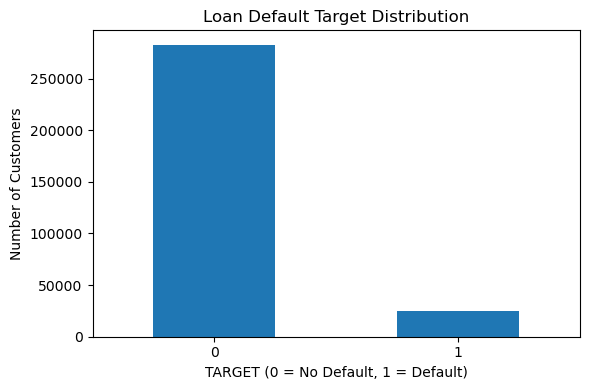

In [9]:
target_col = "TARGET"

if target_col not in application_train.columns:
    raise KeyError("TARGET column was not found in application_train.csv")

target_counts = application_train[target_col].value_counts().sort_index()
target_pct = application_train[target_col].value_counts(normalize=True).sort_index().mul(100).round(2)

target_report = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_pct
})
display(target_report)

plt.figure(figsize=(6, 4))
target_counts.plot(kind="bar")
plt.title("Loan Default Target Distribution")
plt.xlabel("TARGET (0 = No Default, 1 = Default)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Cell 11 — Target interpretation

In [10]:
print("TARGET = 0 represents customers who did not default.")
print("TARGET = 1 represents customers who defaulted.")
print(f"Default rate: {application_train[target_col].mean() * 100:.2f}%")
print("Because the target is imbalanced, Accuracy alone should not be used to select the model.")

TARGET = 0 represents customers who did not default.
TARGET = 1 represents customers who defaulted.
Default rate: 8.07%
Because the target is imbalanced, Accuracy alone should not be used to select the model.


## Cell 12 — Application descriptive statistics

In [11]:
display(application_train.describe(include="all").T.head(80))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,NaN,NaN,NaN,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,NaN,NaN,NaN,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
NAME_CONTRACT_TYPE,307511,2,Cash loans,278232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CODE_GENDER,307511,3,F,202448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FLAG_OWN_CAR,307511,2,N,202924,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
YEARS_BUILD_MEDI,103023.0,NaN,NaN,NaN,0.755746,0.112066,0.0,0.6914,0.7585,0.8256,1.0
COMMONAREA_MEDI,92646.0,NaN,NaN,NaN,0.044595,0.076144,0.0,0.0079,0.0208,0.0513,1.0
ELEVATORS_MEDI,143620.0,NaN,NaN,NaN,0.078078,0.134467,0.0,0.0,0.0,0.12,1.0
ENTRANCES_MEDI,152683.0,NaN,NaN,NaN,0.149213,0.100368,0.0,0.069,0.1379,0.2069,1.0


## Cell 13 — Numerical distributions

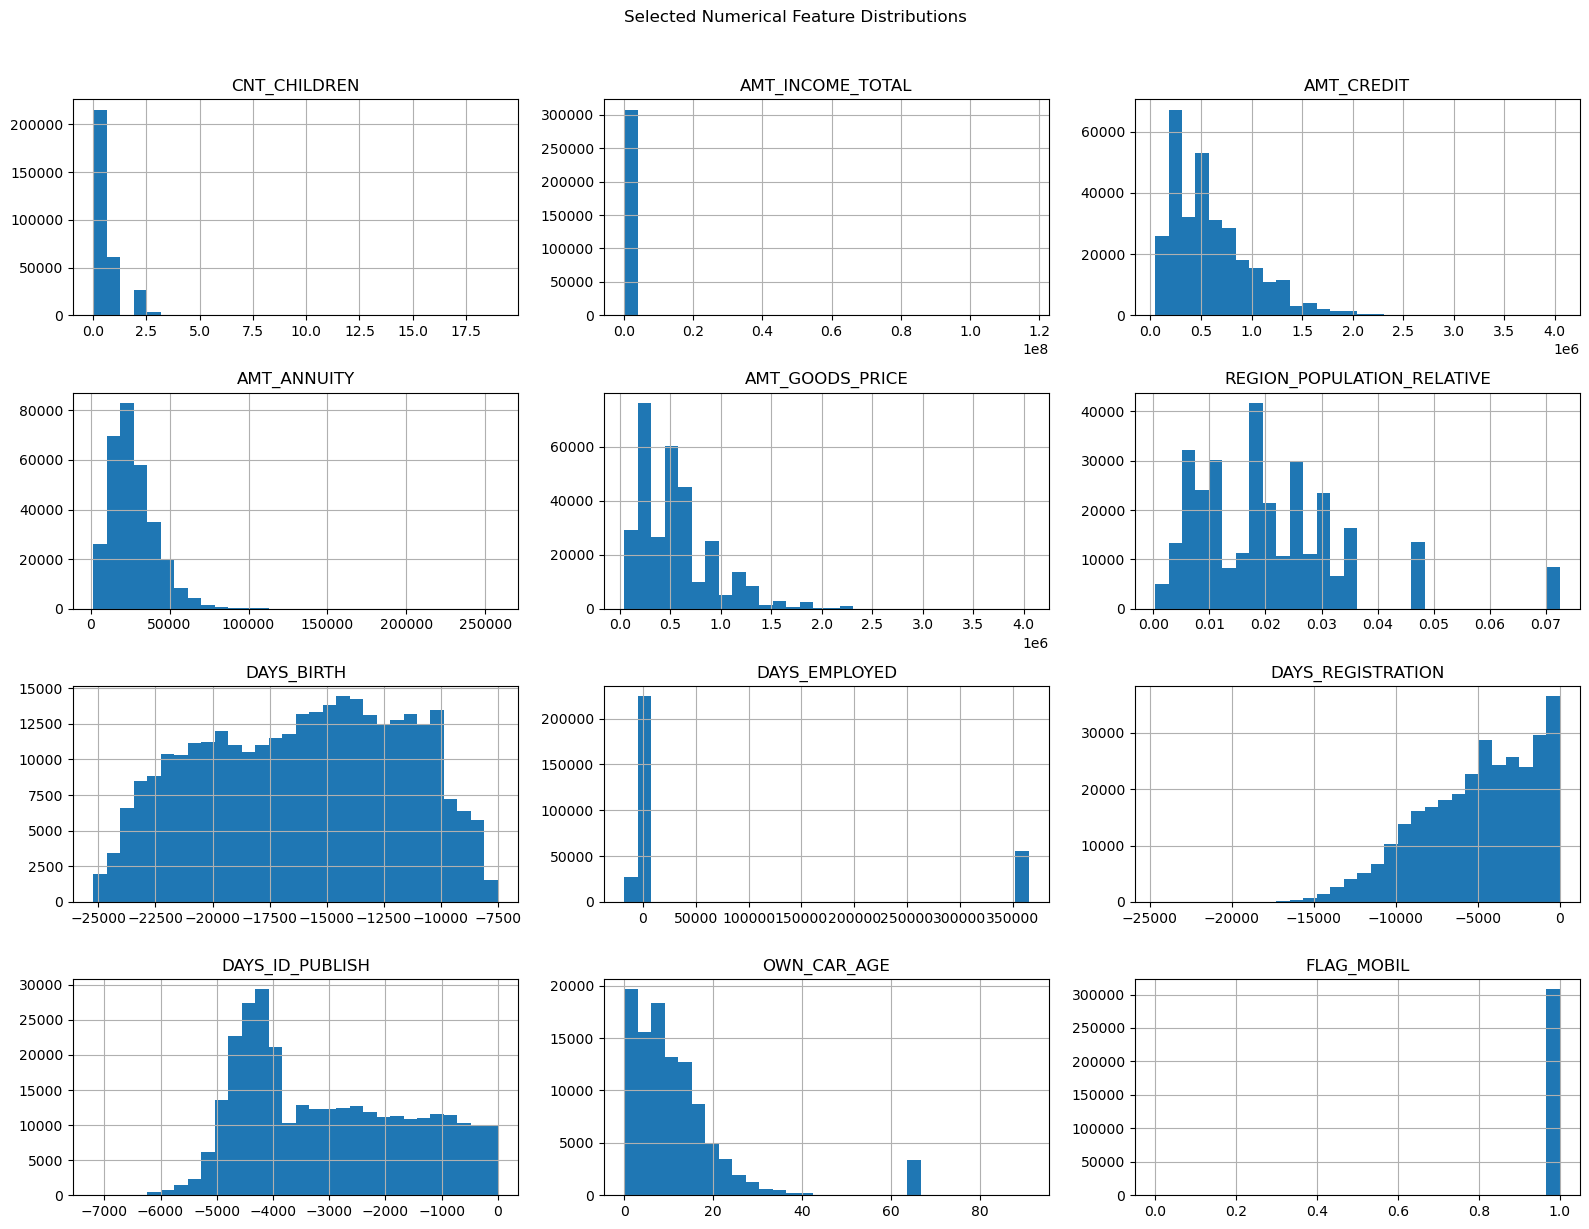

In [12]:
numeric_app = application_train.select_dtypes(include=np.number).columns.tolist()
numeric_app = [c for c in numeric_app if c not in ["SK_ID_CURR", "TARGET"]]

selected_numeric = numeric_app[:12]

application_train[selected_numeric].hist(
    figsize=(16, 12), bins=30
)
plt.suptitle("Selected Numerical Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

## Cell 14 — Important demographic/application distributions

In [13]:
categorical_candidates = [
    c for c in [
        "NAME_CONTRACT_TYPE", "CODE_GENDER", "FLAG_OWN_CAR",
        "FLAG_OWN_REALTY", "NAME_FAMILY_STATUS", "NAME_INCOME_TYPE",
        "NAME_EDUCATION_TYPE", "OCCUPATION_TYPE"
    ] if c in application_train.columns
]

for col in categorical_candidates:
    print("\n", col)
    display(application_train[col].value_counts(dropna=False).head(15))


 NAME_CONTRACT_TYPE


NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64


 CODE_GENDER


CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64


 FLAG_OWN_CAR


FLAG_OWN_CAR
N    202924
Y    104587
Name: count, dtype: int64

... (6 outputs left out)


 NAME_EDUCATION_TYPE


NAME_EDUCATION_TYPE
Secondary / secondary special    218391
Higher education                  74863
Incomplete higher                 10277
Lower secondary                    3816
Academic degree                     164
Name: count, dtype: int64


 OCCUPATION_TYPE


OCCUPATION_TYPE
NaN                      96391
Laborers                 55186
Sales staff              32102
Core staff               27570
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2093
Waiters/barmen staff      1348
Name: count, dtype: int64

## Cell 15 — Default rate by important categorical variables

In [14]:
for col in categorical_candidates:
    summary = (
        application_train.groupby(col, dropna=False)[target_col]
        .agg(["count", "mean"])
        .sort_values("mean", ascending=False)
        .rename(columns={"mean": "Default_Rate"})
    )
    summary["Default_Rate"] = summary["Default_Rate"].mul(100).round(2)
    print("\n" + col)
    display(summary.head(15))


NAME_CONTRACT_TYPE


,count,Default_Rate
NAME_CONTRACT_TYPE,,
Cash loans,278232,8.35
Revolving loans,29279,5.48



CODE_GENDER


,count,Default_Rate
CODE_GENDER,,
M,105059,10.14
F,202448,7.00
XNA,4,0.00



FLAG_OWN_CAR


,count,Default_Rate
FLAG_OWN_CAR,,
N,202924,8.50
Y,104587,7.24


... (6 outputs left out)


NAME_EDUCATION_TYPE


,count,Default_Rate
NAME_EDUCATION_TYPE,,
Lower secondary,3816,10.93
Secondary / secondary special,218391,8.94
Incomplete higher,10277,8.48
Higher education,74863,5.36
Academic degree,164,1.83



OCCUPATION_TYPE


,count,Default_Rate
OCCUPATION_TYPE,,
Low-skill Laborers,2093,17.15
Drivers,18603,11.33
Waiters/barmen staff,1348,11.28
Security staff,6721,10.74
Laborers,55186,10.58
Cooking staff,5946,10.44
Sales staff,32102,9.63
Cleaning staff,4653,9.61
Realty agents,751,7.86


## Cell 16 — Numerical features vs target

In [15]:
important_numeric = [
    c for c in [
        "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
        "AMT_GOODS_PRICE", "DAYS_BIRTH", "DAYS_EMPLOYED",
        "CNT_CHILDREN", "CNT_FAM_MEMBERS"
    ] if c in application_train.columns
]

for col in important_numeric:
    grouped = application_train.groupby(target_col)[col].agg(
        ["count", "mean", "median", "min", "max"]
    )
    print("\n", col)
    display(grouped)


 AMT_INCOME_TOTAL


,count,mean,median,min,max
TARGET,,,,,
0,282686,169077.722266,148500.0,25650.0,18000090.0
1,24825,165611.760906,135000.0,25650.0,117000000.0



 AMT_CREDIT


,count,mean,median,min,max
TARGET,,,,,
0,282686,602648.282002,517788.0,45000.0,4050000.0
1,24825,557778.527674,497520.0,45000.0,4027680.0



 AMT_ANNUITY


,count,mean,median,min,max
TARGET,,,,,
0,282674,27163.623349,24876.0,1615.5,258025.5
1,24825,26481.744290,25263.0,2722.5,149211.0


... (6 outputs left out)


 CNT_CHILDREN


,count,mean,median,min,max
TARGET,,,,,
0,282686,0.412946,0.0,0,19
1,24825,0.463807,0.0,0,11



 CNT_FAM_MEMBERS


,count,mean,median,min,max
TARGET,,,,,
0,282684,2.150154,2.0,1.0,20.0
1,24825,2.181269,2.0,1.0,13.0


## Cell 17 — Correlation with target

In [16]:
corr = application_train.select_dtypes(include=np.number).corr(numeric_only=True)[target_col]
corr = corr.drop(labels=[target_col], errors="ignore").sort_values()

display(pd.DataFrame({
    "Feature": corr.index,
    "Correlation_with_TARGET": corr.values
}).head(20))

display(pd.DataFrame({
    "Feature": corr.index,
    "Correlation_with_TARGET": corr.values
}).tail(20))

,Feature,Correlation_with_TARGET
0,EXT_SOURCE_3,-0.178919
1,EXT_SOURCE_2,-0.160472
2,EXT_SOURCE_1,-0.155317
3,DAYS_EMPLOYED,-0.044932
4,FLOORSMAX_AVG,-0.044003
5,FLOORSMAX_MEDI,-0.043768
6,FLOORSMAX_MODE,-0.043226
7,AMT_GOODS_PRICE,-0.039645
8,REGION_POPULATION_RELATIVE,-0.037227
9,ELEVATORS_AVG,-0.034199


,Feature,Correlation_with_TARGET
85,OBS_60_CNT_SOCIAL_CIRCLE,0.009022
86,OBS_30_CNT_SOCIAL_CIRCLE,0.009131
87,CNT_FAM_MEMBERS,0.009308
88,CNT_CHILDREN,0.019187
89,AMT_REQ_CREDIT_BUREAU_YEAR,0.019930
90,FLAG_WORK_PHONE,0.028524
91,DEF_60_CNT_SOCIAL_CIRCLE,0.031276
92,DEF_30_CNT_SOCIAL_CIRCLE,0.032248
93,LIVE_CITY_NOT_WORK_CITY,0.032518
94,OWN_CAR_AGE,0.037612


## Cell 18 — Correlation heatmap of major numeric variables

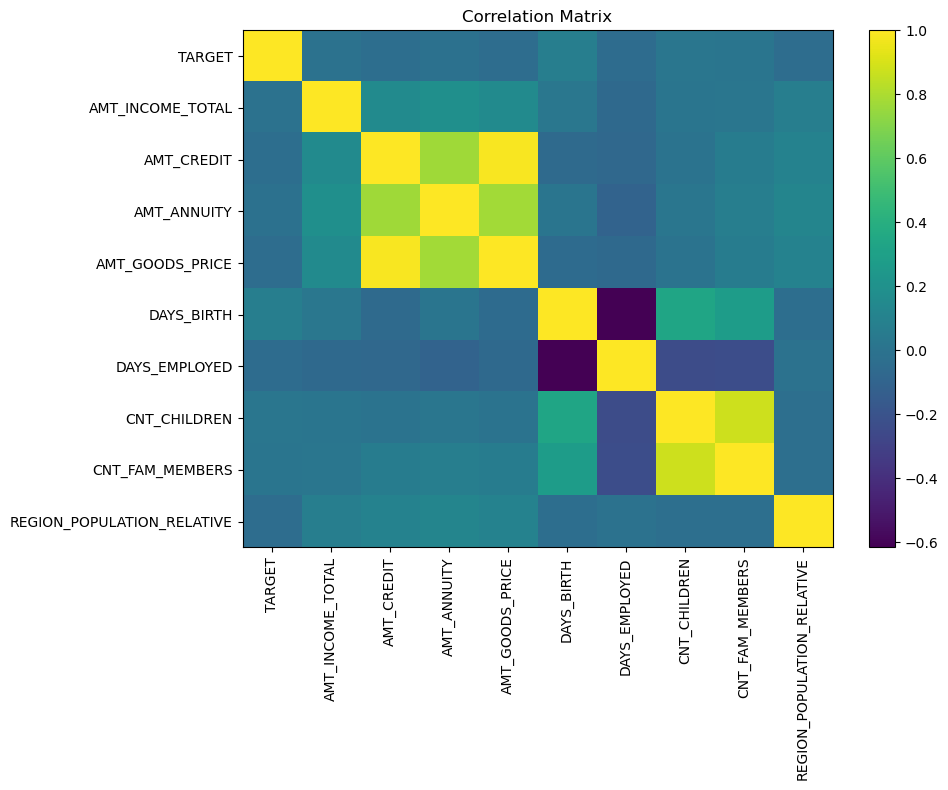

In [17]:
heatmap_cols = [
    c for c in [
        "TARGET", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
        "AMT_GOODS_PRICE", "DAYS_BIRTH", "DAYS_EMPLOYED",
        "CNT_CHILDREN", "CNT_FAM_MEMBERS", "REGION_POPULATION_RELATIVE"
    ] if c in application_train.columns
]

corr_matrix = application_train[heatmap_cols].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, aspect="auto")
plt.colorbar()
plt.xticks(range(len(heatmap_cols)), heatmap_cols, rotation=90)
plt.yticks(range(len(heatmap_cols)), heatmap_cols)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## Cell 19 — Secondary dataset customer coverage

In [18]:
coverage = {}

for name, df in [
    ("bureau", bureau),
    ("POS_CASH_balance", pos_cash),
    ("credit_card_balance", credit_card),
    ("previous_application", previous_application),
    ("installments_payments", installments)
]:
    if "SK_ID_CURR" in df.columns:
        coverage[name] = {
            "Rows": len(df),
            "Unique_Customers": df["SK_ID_CURR"].nunique(),
            "Customers_in_application": df["SK_ID_CURR"].isin(
                application_train["SK_ID_CURR"]
            ).sum()
        }

display(pd.DataFrame(coverage).T)

,Rows,Unique_Customers,Customers_in_application
bureau,1716428,305811,1465325
POS_CASH_balance,10001358,337252,8543375
credit_card_balance,3840312,103558,3227965
previous_application,1670214,338857,1413701
installments_payments,13605401,339587,11591592


## Cell 20 — Bureau analysis

In [19]:
if "CREDIT_ACTIVE" in bureau.columns:
    display(bureau["CREDIT_ACTIVE"].value_counts(dropna=False))

bureau_numeric = bureau.select_dtypes(include=np.number).columns
display(bureau[bureau_numeric].describe().T.head(30))

CREDIT_ACTIVE
Closed      1079273
Active       630607
Sold           6527
Bad debt         21
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,1716428.0,2.782149e+05,1.029386e+05,100001.000,188866.75,278055.0,367426.00,4.562550e+05
SK_ID_BUREAU,1716428.0,5.924434e+06,5.322657e+05,5000000.000,5463953.75,5926303.5,6385681.25,6.843457e+06
DAYS_CREDIT,1716428.0,-1.142108e+03,7.951649e+02,-2922.000,-1666.00,-987.0,-474.00,0.000000e+00
CREDIT_DAY_OVERDUE,1716428.0,8.181666e-01,3.654443e+01,0.000,0.00,0.0,0.00,2.792000e+03
DAYS_CREDIT_ENDDATE,1610875.0,5.105174e+02,4.994220e+03,-42060.000,-1138.00,-330.0,474.00,3.119900e+04
DAYS_ENDDATE_FACT,1082775.0,-1.017437e+03,7.140106e+02,-42023.000,-1489.00,-897.0,-425.00,0.000000e+00
AMT_CREDIT_MAX_OVERDUE,591940.0,3.825418e+03,2.060316e+05,0.000,0.00,0.0,0.00,1.159872e+08
CNT_CREDIT_PROLONG,1716428.0,6.410406e-03,9.622391e-02,0.000,0.00,0.0,0.00,9.000000e+00
AMT_CREDIT_SUM,1716415.0,3.549946e+05,1.149811e+06,0.000,51300.00,125518.5,315000.00,5.850000e+08
AMT_CREDIT_SUM_DEBT,1458759.0,1.370851e+05,6.774011e+05,-4705600.320,0.00,0.0,40153.50,1.701000e+08


## Cell 21 — Bureau balance analysis

In [20]:
display(bureau_balance.head())
print("Unique bureau accounts:", bureau_balance["SK_ID_BUREAU"].nunique())
print("Status distribution:")
display(bureau_balance["STATUS"].value_counts(dropna=False).sort_index())
display(bureau_balance["MONTHS_BALANCE"].describe())

,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


Unique bureau accounts: 817395
Status distribution:


STATUS
0     7499507
1      242347
2       23419
3        8924
4        5847
5       62406
C    13646993
X     5810482
Name: count, dtype: int64

count    2.729992e+07
mean    -3.074169e+01
std      2.386451e+01
min     -9.600000e+01
25%     -4.600000e+01
50%     -2.500000e+01
75%     -1.100000e+01
max      0.000000e+00
Name: MONTHS_BALANCE, dtype: float64

## Cell 22 — POS Cash analysis

In [21]:
print("SK_ID_CURR:", pos_cash["SK_ID_CURR"].nunique())
if "NAME_CONTRACT_STATUS" in pos_cash.columns:
    display(pos_cash["NAME_CONTRACT_STATUS"].value_counts(dropna=False))
display(pos_cash.select_dtypes(include=np.number).describe().T.head(30))

SK_ID_CURR: 337252


NAME_CONTRACT_STATUS
Active                   9151119
Completed                 744883
Signed                     87260
Demand                      7065
Returned to the store       5461
Approved                    4917
Amortized debt               636
Canceled                      15
XNA                            2
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
SK_ID_PREV,10001358.0,1.903217e+06,535846.530722,1000001.0,1434405.0,1896565.0,2368963.0,2843499.0
SK_ID_CURR,10001358.0,2.784039e+05,102763.745090,100001.0,189550.0,278654.0,367429.0,456255.0
MONTHS_BALANCE,10001358.0,-3.501259e+01,26.066570,-96.0,-54.0,-28.0,-13.0,-1.0
CNT_INSTALMENT,9975287.0,1.708965e+01,11.995056,1.0,10.0,12.0,24.0,92.0
CNT_INSTALMENT_FUTURE,9975271.0,1.048384e+01,11.109058,0.0,3.0,7.0,14.0,85.0
SK_DPD,10001358.0,1.160693e+01,132.714043,0.0,0.0,0.0,0.0,4231.0
SK_DPD_DEF,10001358.0,6.544684e-01,32.762491,0.0,0.0,0.0,0.0,3595.0


## Cell 23 — Credit card analysis

In [22]:
print("SK_ID_CURR:", credit_card["SK_ID_CURR"].nunique())
display(credit_card.select_dtypes(include=np.number).describe().T.head(30))

SK_ID_CURR: 103558


,count,mean,std,min,25%,50%,75%,max
SK_ID_PREV,3840312.0,1.904504e+06,536469.470563,1000018.000,1434385.00,1897122.0,2.369328e+06,2843496.000
SK_ID_CURR,3840312.0,2.783242e+05,102704.475133,100006.000,189517.00,278396.0,3.675800e+05,456250.000
MONTHS_BALANCE,3840312.0,-3.452192e+01,26.667751,-96.000,-55.00,-28.0,-1.100000e+01,-1.000
AMT_BALANCE,3840312.0,5.830016e+04,106307.031025,-420250.185,0.00,0.0,8.904669e+04,1505902.185
AMT_CREDIT_LIMIT_ACTUAL,3840312.0,1.538080e+05,165145.699523,0.000,45000.00,112500.0,1.800000e+05,1350000.000
AMT_DRAWINGS_ATM_CURRENT,3090496.0,5.961325e+03,28225.688579,-6827.310,0.00,0.0,0.000000e+00,2115000.000
AMT_DRAWINGS_CURRENT,3840312.0,7.433388e+03,33846.077334,-6211.620,0.00,0.0,0.000000e+00,2287098.315
AMT_DRAWINGS_OTHER_CURRENT,3090496.0,2.881696e+02,8201.989345,0.000,0.00,0.0,0.000000e+00,1529847.000
AMT_DRAWINGS_POS_CURRENT,3090496.0,2.968805e+03,20796.887047,0.000,0.00,0.0,0.000000e+00,2239274.160
AMT_INST_MIN_REGULARITY,3535076.0,3.540204e+03,5600.154122,0.000,0.00,0.0,6.633911e+03,202882.005


## Cell 24 — Previous application analysis

In [23]:
print("SK_ID_CURR:", previous_application["SK_ID_CURR"].nunique())
if "NAME_CONTRACT_STATUS" in previous_application.columns:
    display(previous_application["NAME_CONTRACT_STATUS"].value_counts(dropna=False).head(20))
display(previous_application.select_dtypes(include=np.number).describe().T.head(30))

SK_ID_CURR: 338857


NAME_CONTRACT_STATUS
Approved        1036781
Canceled         316319
Refused          290678
Unused offer      26436
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
SK_ID_PREV,1670214.0,1.923089e+06,532597.958696,1.000001e+06,1.461857e+06,1.923110e+06,2.384280e+06,2845382.000
SK_ID_CURR,1670214.0,2.783572e+05,102814.823849,1.000010e+05,1.893290e+05,2.787145e+05,3.675140e+05,456255.000
AMT_ANNUITY,1297979.0,1.595512e+04,14782.137335,0.000000e+00,6.321780e+03,1.125000e+04,2.065842e+04,418058.145
AMT_APPLICATION,1670214.0,1.752339e+05,292779.762387,0.000000e+00,1.872000e+04,7.104600e+04,1.803600e+05,6905160.000
AMT_CREDIT,1670213.0,1.961140e+05,318574.616546,0.000000e+00,2.416050e+04,8.054100e+04,2.164185e+05,6905160.000
AMT_DOWN_PAYMENT,774370.0,6.697402e+03,20921.495410,-9.000000e-01,0.000000e+00,1.638000e+03,7.740000e+03,3060045.000
AMT_GOODS_PRICE,1284699.0,2.278473e+05,315396.557937,0.000000e+00,5.084100e+04,1.123200e+05,2.340000e+05,6905160.000
HOUR_APPR_PROCESS_START,1670214.0,1.248418e+01,3.334028,0.000000e+00,1.000000e+01,1.200000e+01,1.500000e+01,23.000
NFLAG_LAST_APPL_IN_DAY,1670214.0,9.964675e-01,0.059330,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000
RATE_DOWN_PAYMENT,774370.0,7.963682e-02,0.107823,-1.497876e-05,0.000000e+00,5.160508e-02,1.089091e-01,1.000


## Cell 25 — Installments payment analysis

In [24]:
print("SK_ID_CURR:", installments["SK_ID_CURR"].nunique())
display(installments.select_dtypes(include=np.number).describe().T.head(30))

SK_ID_CURR: 339587


,count,mean,std,min,25%,50%,75%,max
SK_ID_PREV,13605401.0,1.903365e+06,536202.905546,1000001.0,1434191.000,1896520.000,2369094.000,2843499.000
SK_ID_CURR,13605401.0,2.784449e+05,102718.310411,100001.0,189639.000,278685.000,367530.000,456255.000
NUM_INSTALMENT_VERSION,13605401.0,8.566373e-01,1.035216,0.0,0.000,1.000,1.000,178.000
NUM_INSTALMENT_NUMBER,13605401.0,1.887090e+01,26.664067,1.0,4.000,8.000,19.000,277.000
DAYS_INSTALMENT,13605401.0,-1.042270e+03,800.946284,-2922.0,-1654.000,-818.000,-361.000,-1.000
DAYS_ENTRY_PAYMENT,13602496.0,-1.051114e+03,800.585883,-4921.0,-1662.000,-827.000,-370.000,-1.000
AMT_INSTALMENT,13605401.0,1.705091e+04,50570.254429,0.0,4226.085,8884.080,16710.210,3771487.845
AMT_PAYMENT,13602496.0,1.723822e+04,54735.783981,0.0,3398.265,8125.515,16108.425,3771487.845


## Cell 26 — Feature engineering functions

In [25]:
def aggregate_customer_table(df, prefix, group_col="SK_ID_CURR"):
    numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
    numeric_cols = [c for c in numeric_cols if c != group_col]

    if not numeric_cols:
        return df[[group_col]].drop_duplicates().set_index(group_col)

    agg = df.groupby(group_col)[numeric_cols].agg(["mean", "sum", "min", "max"])
    agg.columns = [f"{prefix}_{col}_{stat}" for col, stat in agg.columns]
    return agg

def add_customer_aggregate(base, df, prefix):
    agg = aggregate_customer_table(df, prefix)
    return base.join(agg, on="SK_ID_CURR")

## Cell 27 — Create customer-level historical features

In [26]:
model_df = application_train.copy()

model_df = add_customer_aggregate(model_df, bureau, "BUREAU")
model_df = add_customer_aggregate(model_df, pos_cash, "POS")
model_df = add_customer_aggregate(model_df, credit_card, "CC")
model_df = add_customer_aggregate(model_df, previous_application, "PREV")
model_df = add_customer_aggregate(model_df, installments, "INST")

print("Customer-level modeling dataset:", model_df.shape)

Customer-level modeling dataset: (307511, 390)


## Cell 28 — Additional customer history counts

In [27]:
history_counts = pd.DataFrame(index=application_train["SK_ID_CURR"])

for prefix, df in [
    ("BUREAU", bureau),
    ("POS", pos_cash),
    ("CC", credit_card),
    ("PREV", previous_application),
    ("INST", installments)
]:
    counts = df.groupby("SK_ID_CURR").size().rename(f"{prefix}_RECORD_COUNT")
    history_counts = history_counts.join(counts, how="left")

history_counts = history_counts.fillna(0)
model_df = model_df.drop(
    columns=[c for c in model_df.columns if c in history_counts.columns],
    errors="ignore"
).join(history_counts, on="SK_ID_CURR")

print(model_df.shape)

(307511, 395)


## Cell 29 — Final data-quality checks for modeling data

In [28]:
print("Rows:", len(model_df))
print("Duplicate rows:", model_df.duplicated().sum())
print("Duplicate SK_ID_CURR:", model_df["SK_ID_CURR"].duplicated().sum())
print("Missing target:", model_df[target_col].isna().sum())
print("Infinite values:", np.isinf(model_df.select_dtypes(include=np.number)).sum().sum())

Rows: 307511
Duplicate rows: 0
Duplicate SK_ID_CURR: 0
Missing target: 0
Infinite values: 0


## Cell 30 — Remove identifier and separate X/y

In [29]:
X = model_df.drop(columns=[target_col, "SK_ID_CURR"])
y = model_df[target_col].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target distribution:")
display(y.value_counts().sort_index())

X shape: (307511, 393)
y shape: (307511,)
Target distribution:


TARGET
0    282686
1     24825
Name: count, dtype: int64

## Cell 31 — Identify numerical and categorical features

In [30]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Categorical columns:")
print(categorical_features)

Numerical features: 377
Categorical features: 16
Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


## Cell 32 — Train/test split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training default rate:", y_train.mean())
print("Testing default rate:", y_test.mean())

Training rows: 246008
Testing rows: 61503
Training default rate: 0.08072908198107379
Testing default rate: 0.08072776937710356


## Cell 33 — Preprocessing pipeline

In [32]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

## Cell 34 — Define multiple predictive models

In [33]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=500,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}

## Cell 35 — Train models and calculate metrics

In [34]:
results = []
fitted_models = {}
predictions = {}

for name, estimator in models.items():
    print("Training:", name)

    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)

    if hasattr(pipe, "predict_proba"):
        y_prob = pipe.predict_proba(X_test)[:, 1]
    else:
        y_prob = pipe.decision_function(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
        "PR_AUC": average_precision_score(y_test, y_prob)
    })

    fitted_models[name] = pipe
    predictions[name] = {"pred": y_pred, "prob": y_prob}

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
display(results_df.round(4))

Training: Logistic Regression
Training: Decision Tree
Training: Random Forest


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest,0.8091,0.2073,0.4834,0.2902,0.7461,0.2193
1,Logistic Regression,0.7067,0.1730,0.6969,0.2772,0.7711,0.2566
2,Decision Tree,0.6606,0.1484,0.6761,0.2433,0.7155,0.1952


## Cell 36 — Model comparison report

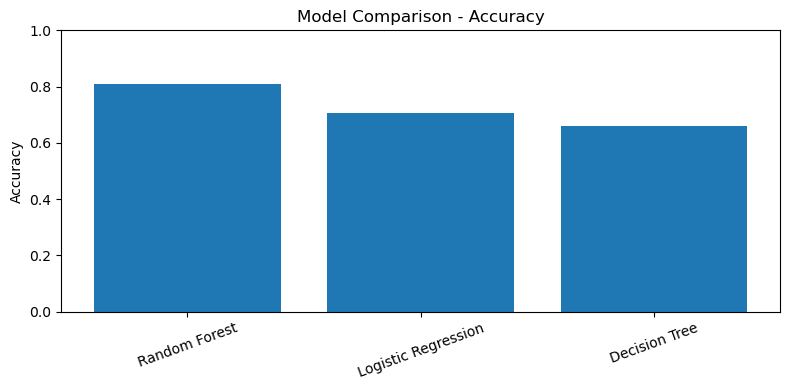

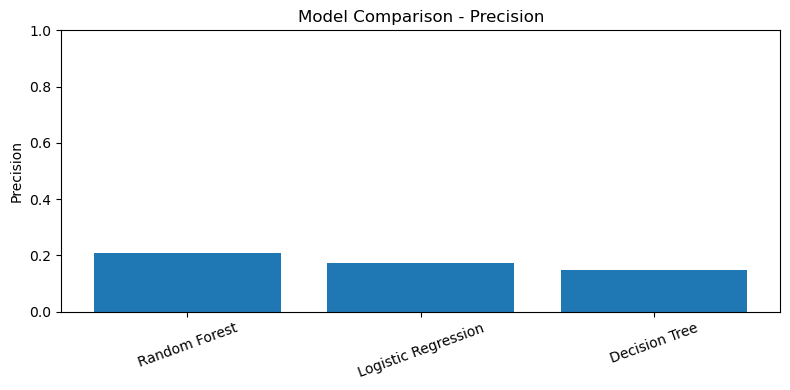

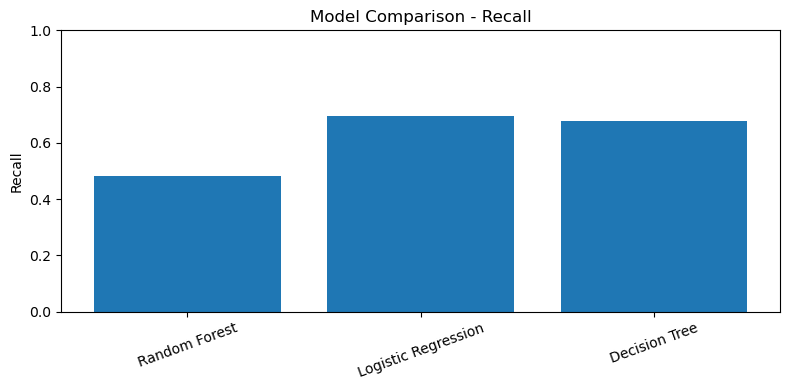

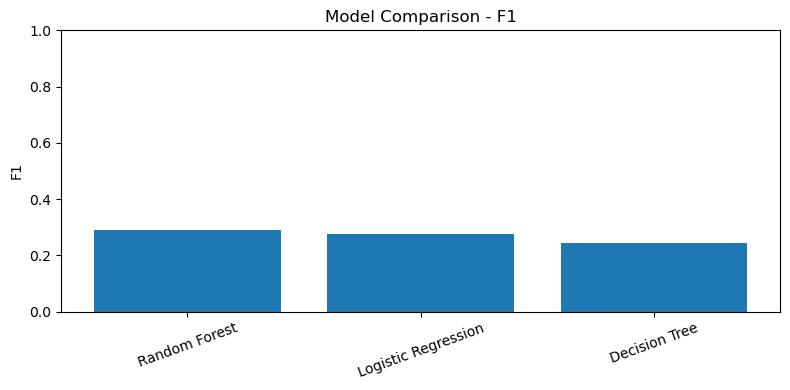

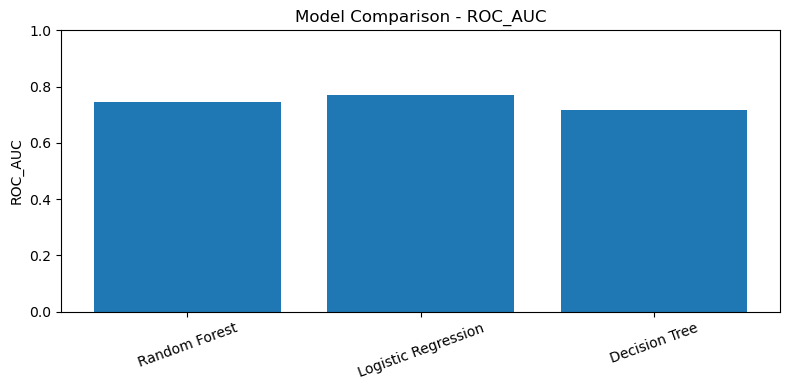

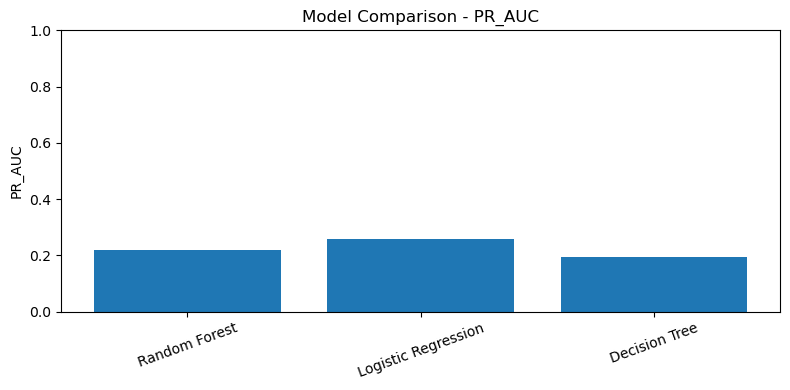

In [35]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]

for metric in metrics_to_plot:
    plt.figure(figsize=(8, 4))
    plt.bar(results_df["Model"], results_df[metric])
    plt.title(f"Model Comparison - {metric}")
    plt.ylabel(metric)
    plt.xticks(rotation=20)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

## Cell 37 — Confusion matrices

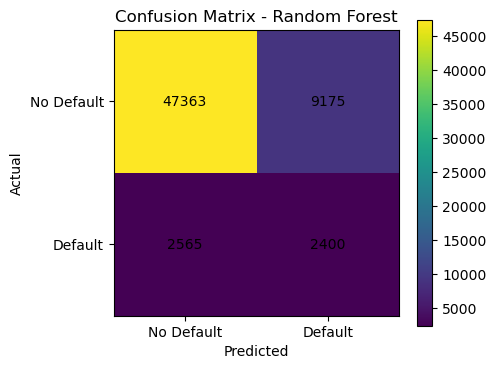

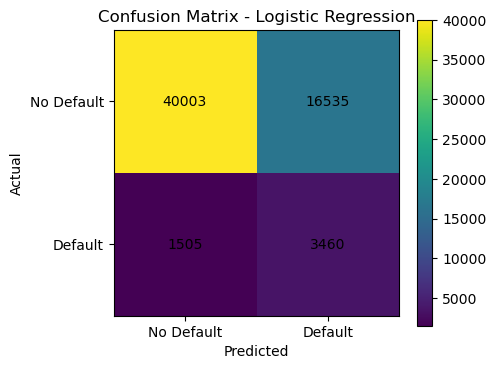

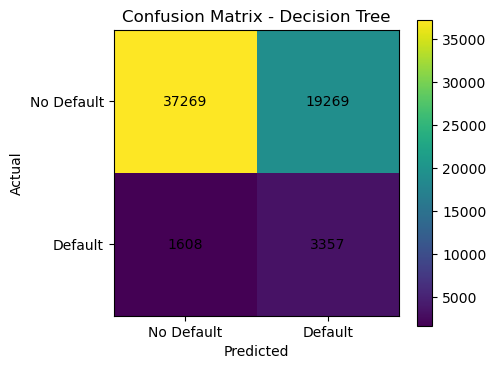

In [36]:
for name in results_df["Model"]:
    cm = confusion_matrix(y_test, predictions[name]["pred"])

    plt.figure(figsize=(5, 4))
    plt.imshow(cm)
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.xticks([0, 1], ["No Default", "Default"])
    plt.yticks([0, 1], ["No Default", "Default"])

    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha="center", va="center")

    plt.colorbar()
    plt.tight_layout()
    plt.show()

## Cell 38 — Classification reports

In [37]:
for name in results_df["Model"]:
    print("\n" + "=" * 80)
    print(name)
    print(classification_report(
        y_test,
        predictions[name]["pred"],
        target_names=["No Default", "Default"],
        zero_division=0
    ))


Random Forest
              precision    recall  f1-score   support

  No Default       0.95      0.84      0.89     56538
     Default       0.21      0.48      0.29      4965

    accuracy                           0.81     61503
   macro avg       0.58      0.66      0.59     61503
weighted avg       0.89      0.81      0.84     61503


Logistic Regression
              precision    recall  f1-score   support

  No Default       0.96      0.71      0.82     56538
     Default       0.17      0.70      0.28      4965

    accuracy                           0.71     61503
   macro avg       0.57      0.70      0.55     61503
weighted avg       0.90      0.71      0.77     61503


Decision Tree
              precision    recall  f1-score   support

  No Default       0.96      0.66      0.78     56538
     Default       0.15      0.68      0.24      4965

    accuracy                           0.66     61503
   macro avg       0.55      0.67      0.51     61503
weighted avg       0.89

## Cell 39 — ROC curves

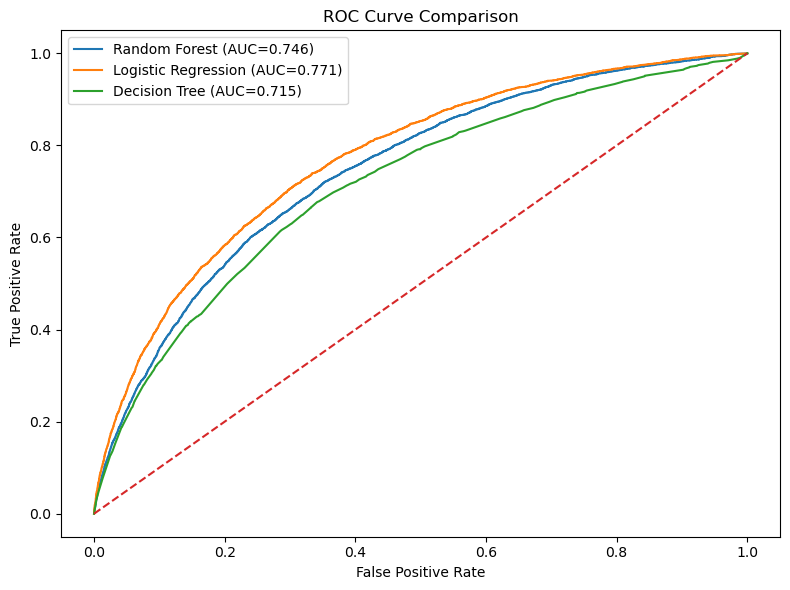

In [38]:
plt.figure(figsize=(8, 6))

for name in results_df["Model"]:
    y_prob = predictions[name]["prob"]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_value = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()

## Cell 40 — Select candidate production model

In [39]:
# For loan-default risk, F1 is used as the primary selection metric
# because the target is imbalanced and both false positives and false negatives matter.

best_model_name = results_df.sort_values(
    ["F1", "ROC_AUC", "Recall"],
    ascending=False
).iloc[0]["Model"]

best_model = fitted_models[best_model_name]

print("Candidate production model:", best_model_name)
display(
    results_df[results_df["Model"] == best_model_name]
    .round(4)
)

Candidate production model: Random Forest


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest,0.8091,0.2073,0.4834,0.2902,0.7461,0.2193


## Cell 41 — Candidate model interpretation

In [40]:
best_pred = predictions[best_model_name]["pred"]

tn, fp, fn, tp = confusion_matrix(y_test, best_pred).ravel()

print("Candidate model:", best_model_name)
print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives  :", tp)
print()
print("Important: this is a candidate model based on one hold-out test split.")
print("A banking production model requires additional validation, monitoring,")
print("fairness checks, stability testing and business-approved risk thresholds.")

Candidate model: Random Forest
True Negatives : 47363
False Positives: 9175
False Negatives: 2565
True Positives  : 2400

Important: this is a candidate model based on one hold-out test split.
A banking production model requires additional validation, monitoring,
fairness checks, stability testing and business-approved risk thresholds.


## Cell 42 — Feature importance for Random Forest

In [41]:
rf_pipe = fitted_models["Random Forest"]

feature_names = rf_pipe.named_steps["preprocessor"].get_feature_names_out()
rf_importance = rf_pipe.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importance
}).sort_values("Importance", ascending=False)

display(importance_df.head(25))

,Feature,Importance
28,num__EXT_SOURCE_2,0.068137
29,num__EXT_SOURCE_3,0.066677
27,num__EXT_SOURCE_1,0.026537
6,num__DAYS_BIRTH,0.018338
108,num__BUREAU_DAYS_CREDIT_mean,0.016728
111,num__BUREAU_DAYS_CREDIT_max,0.013392
7,num__DAYS_EMPLOYED,0.012794
370,num__INST_AMT_PAYMENT_min,0.010478
148,num__BUREAU_DAYS_CREDIT_UPDATE_mean,0.009245
117,num__BUREAU_DAYS_CREDIT_ENDDATE_sum,0.008665


## Cell 43 — Plot top feature importances

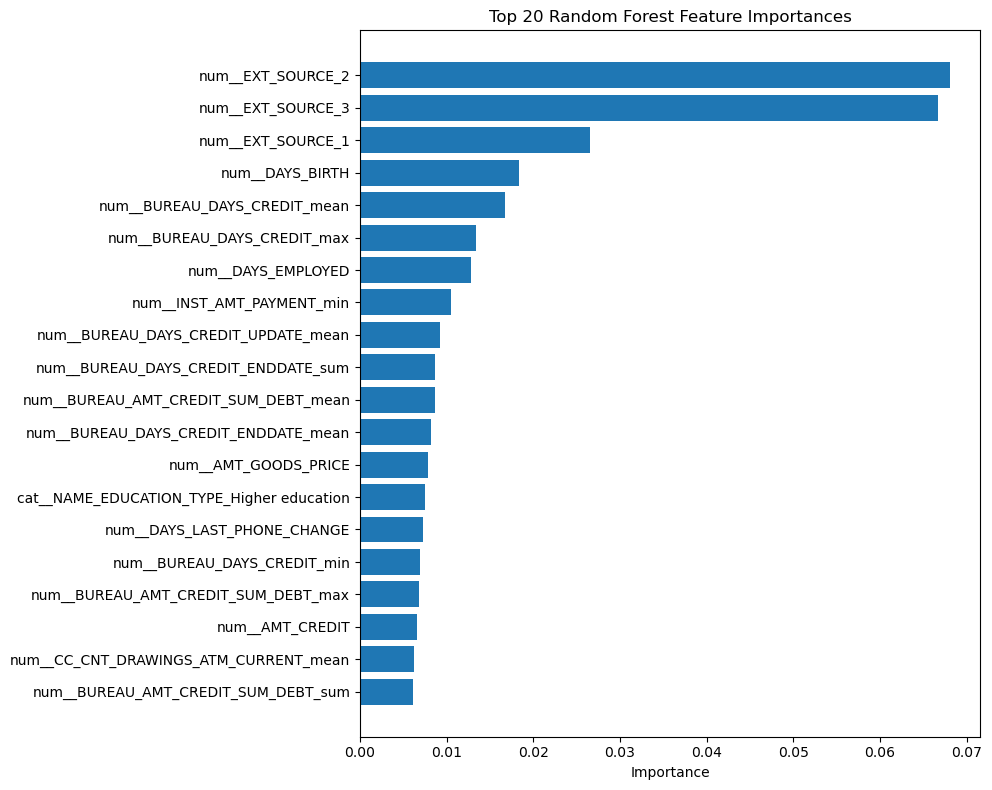

In [42]:
top_features = importance_df.head(20).sort_values("Importance")

plt.figure(figsize=(10, 8))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Cell 44 — Customer risk segmentation

In [43]:
risk_view = pd.DataFrame({
    "Actual_Default": y_test.values,
    "Predicted_Default": best_pred,
    "Predicted_Default_Probability": predictions[best_model_name]["prob"]
})

risk_view["Risk_Segment"] = pd.cut(
    risk_view["Predicted_Default_Probability"],
    bins=[-np.inf, 0.20, 0.50, np.inf],
    labels=["Lower Risk", "Medium Risk", "Higher Risk"]
)

display(
    risk_view.groupby("Risk_Segment", observed=False)
    .agg(
        Customers=("Actual_Default", "size"),
        Actual_Default_Rate=("Actual_Default", "mean"),
        Average_Predicted_Risk=("Predicted_Default_Probability", "mean")
    )
    .reset_index()
)

,Risk_Segment,Customers,Actual_Default_Rate,Average_Predicted_Risk
0,Lower Risk,2002,0.013487,0.181576
1,Medium Risk,47926,0.052957,0.345405
2,Higher Risk,11575,0.207343,0.580881


## Cell 45 — Report on challenges faced and techniques used

In [44]:
challenge_report = pd.DataFrame([
    {
        "Challenge": "Class imbalance in TARGET",
        "Technique Used": "Stratified train-test split and class_weight='balanced'",
        "Reason": "Keeps both classes represented and gives more importance to the minority default class."
    },
    {
        "Challenge": "Many missing values",
        "Technique Used": "Median imputation for numeric features and most-frequent imputation for categorical features",
        "Reason": "Allows models to train without deleting large numbers of customers."
    },
    {
        "Challenge": "Categorical variables",
        "Technique Used": "One-hot encoding with handle_unknown='ignore'",
        "Reason": "Converts categories to model-ready numeric features and handles unseen test categories safely."
    },
    {
        "Challenge": "Different numerical scales",
        "Technique Used": "StandardScaler",
        "Reason": "Places numerical variables on comparable scales for linear models."
    },
    {
        "Challenge": "Multiple historical tables",
        "Technique Used": "Customer-level aggregation using SK_ID_CURR",
        "Reason": "Converts transaction/history records into one modeling row per customer."
    },
    {
        "Challenge": "Customer identifier leakage",
        "Technique Used": "Removed SK_ID_CURR before modeling",
        "Reason": "An identifier is not a meaningful predictive business feature."
    },
    {
        "Challenge": "Model selection",
        "Technique Used": "Accuracy, Precision, Recall, F1, ROC-AUC and PR-AUC",
        "Reason": "Multiple metrics give a more complete view than accuracy alone."
    }
])

display(challenge_report)

,Challenge,Technique Used,Reason
0,Class imbalance in TARGET,Stratified train-test split and class_weight='...,Keeps both classes represented and gives more ...
1,Many missing values,Median imputation for numeric features and mos...,Allows models to train without deleting large ...
2,Categorical variables,One-hot encoding with handle_unknown='ignore',Converts categories to model-ready numeric fea...
3,Different numerical scales,StandardScaler,Places numerical variables on comparable scale...
4,Multiple historical tables,Customer-level aggregation using SK_ID_CURR,Converts transaction/history records into one ...
5,Customer identifier leakage,Removed SK_ID_CURR before modeling,An identifier is not a meaningful predictive b...
6,Model selection,"Accuracy, Precision, Recall, F1, ROC-AUC and P...",Multiple metrics give a more complete view tha...


## Cell 46 — Banking/business suggestions

## Cell 46 — Business recommendations
The model can be used as a **decision-support** tool for loan-risk assessment.

- Use predicted default probability to prioritize applications for additional review.
- Combine historical credit behaviour with current application information.
- Use risk segments to support differentiated verification or underwriting workflows.
- Do not use the model as the only basis for loan approval or rejection.
- Monitor model performance, drift, fairness and stability after deployment.

## Cell 47 — Limitations
- The evaluation is based on one stratified hold-out split.
- Historical data may contain bias or changes in customer behaviour over time.
- Aggregated historical variables do not automatically establish causation.
- Model probabilities should be calibrated before being used as business risk scores.
- Production use requires temporal validation, fairness testing, explainability, monitoring and compliance review.

## Cell 48 — Final conclusion
The project combines exploratory data analysis, customer-level historical feature engineering and multiple classification algorithms for home-loan default-risk analysis.

The model comparison report uses Accuracy, Precision, Recall, F1, ROC-AUC and PR-AUC. Because the target is imbalanced, F1, Recall, ROC-AUC and PR-AUC are especially useful alongside Accuracy.

The selected model is treated as a **candidate production model**, not as a final banking decision system. Further validation on future/unseen data is required before deployment.

## Cell 49 — Save model comparison report

In [45]:
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

results_path = OUTPUT_DIR / "model_comparison_report.csv"
results_df.to_csv(results_path, index=False)

print("Saved:", results_path)

Saved: <project-folder>\outputs\model_comparison_report.csv


## Cell 50 — Save the candidate model

In [46]:
import joblib

model_path = OUTPUT_DIR / "home_loan_default_candidate_model.pkl"

joblib.dump(
    {
        "model": best_model,
        "model_name": best_model_name,
        "features": X.columns.tolist(),
        "selection_metric": "F1",
        "random_state": RANDOM_STATE
    },
    model_path
)

print("Saved candidate model:", model_path)
print("Candidate model:", best_model_name)

Saved candidate model: <project-folder>\outputs\home_loan_default_candidate_model.pkl
Candidate model: Random Forest
